# Análisis de precios de alquiler en CABA

## Objetivo

Responder las preguntas del proyecto a partir del dataset limpio generado por `src/cleaning.py` (`python -m src.cleaning`).

## Decisiones metodológicas

- **Moneda común:** todos los precios están en USD. Los avisos en pesos se convirtieron con el dólar MEP del día del scraping.
- **Una fila por departamento:** el dataset conserva el historial de cada aviso. Para comparar barrios se usa solo la publicación más reciente de cada `id`, así cada departamento cuenta una vez.
- **Mediana, no promedio:** la distribución de precios es asimétrica, y unos pocos departamentos muy caros inflan el promedio.
- **Mínimo de 30 departamentos por barrio** para incluirlo en los rankings.

In [1]:
import sys
sys.path.append("..")

import pandas as pd

from src.analysis import (
    elasticidad_precio_superficie,
    m2_por_presupuesto,
    resumen_por_ambientes,
    resumen_por_barrio,
    ultima_publicacion,
    usd_m2_por_ambientes_en_barrio,
    usd_m2_por_superficie,
)
from src.charts import (
    guardar,
    m2_con_presupuesto,
    precio_por_ambientes,
    ranking_usd_m2_por_barrio,
    usd_m2_chico_vs_grande,
    usd_m2_por_superficie_chart,
)

pd.set_option("display.float_format", "{:,.1f}".format)

In [2]:
df = pd.read_parquet("../data/processed/alquileres_limpio.parquet")
deptos = ultima_publicacion(df)

print(f"Publicaciones en el dataset limpio: {len(df):,}")
print(f"Departamentos únicos: {len(deptos):,}")

Publicaciones en el dataset limpio: 52,618
Departamentos únicos: 29,038


## 1. ¿Qué barrios tienen el precio más alto por m²?

Se calcula la mediana del alquiler mensual en USD por m² de cada barrio.

In [3]:
resumen = resumen_por_barrio(deptos)
mediana_caba = deptos["precio_usd_m2"].median()

print(f"Mediana CABA: USD {mediana_caba:.1f} por m²")
print(f"Barrios incluidos: {len(resumen)} de {deptos['barrio'].nunique()}")
resumen

Mediana CABA: USD 10.2 por m²
Barrios incluidos: 40 de 48


,propiedades,comuna,mediana_usd_m2,p25_usd_m2,p75_usd_m2,mediana_precio_usd,mediana_m2
barrio,,,,,,,
Puerto Madero,1409,1,22.7,18.1,28.1,"2,250.0",96.0
Palermo,6734,14,11.8,9.6,15.6,600.0,50.0
Núñez,997,13,11.2,9.4,14.0,551.6,50.0
Belgrano,2998,13,10.8,9.0,13.6,573.3,51.0
Retiro,637,1,10.7,8.3,13.5,622.6,60.0
Recoleta,4476,2,10.2,8.5,12.8,540.2,53.0
Colegiales,547,13,10.1,8.7,12.5,487.9,45.0
Chacarita,198,15,9.9,8.7,11.6,399.4,40.5
Saavedra,307,12,9.8,8.7,11.6,450.5,45.0


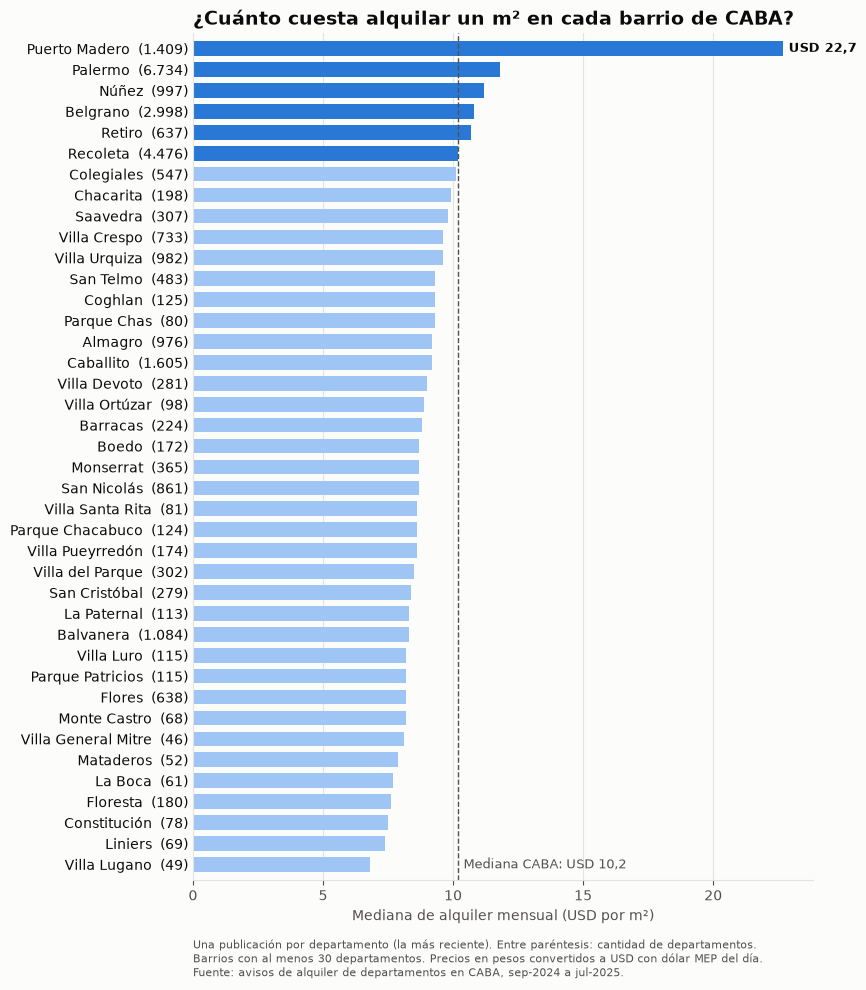

In [4]:
fig = ranking_usd_m2_por_barrio(resumen, mediana_caba)
guardar(fig, "01_usd_m2_por_barrio");

### Conclusiones

- **Puerto Madero es un mercado aparte:** USD 22,7 por m², más del doble de la mediana de CABA (USD 10,2) y casi el doble del segundo barrio, Palermo (USD 11,8). Además sus departamentos son más grandes (mediana de 96 m² contra unos 45 a 50 m² en el resto), así que el alquiler mensual típico llega a USD 2.250.
- **El corredor norte encabeza el ranking:** Palermo, Núñez, Belgrano, Retiro y Recoleta son los únicos barrios por encima de la mediana de la ciudad.
- **Los barrios del sur y del oeste son los más accesibles:** Villa Lugano (USD 6,8), Liniers, Constitución, Floresta y La Boca están entre USD 6,8 y 7,7 por m².
- **Fuera de los extremos, las diferencias son chicas:** más de 30 barrios están entre USD 7,5 y 10 por m². Por ejemplo, entre Chacarita (USD 9,9) y Flores (USD 8,2) hay USD 1,7 por m². En un departamento típico de 45 m², eso son unos USD 75 por mes.

**Limitaciones:** son precios publicados, no precios de cierre. Además, 8 barrios quedaron fuera por tener menos de 30 departamentos publicados: Agronomía, Nueva Pompeya, Parque Avellaneda, Versalles, Villa Real, Villa Riachuelo, Villa Soldati y Vélez Sársfield.

## 2. ¿Cómo influye la cantidad de ambientes en el precio?

Los departamentos de 5 o más ambientes se agrupan en una categoría (`5+`) porque son pocos.

In [5]:
por_ambientes = resumen_por_ambientes(deptos)
por_ambientes

,propiedades,mediana_precio_usd,p25_precio_usd,p75_precio_usd,mediana_m2,mediana_usd_m2,pct_publicado_en_usd,pct_corredor_norte,aumento_vs_anterior_%
ambientes_grupo,,,,,,,,,
1,8137,354.6,290.9,450.0,35.0,10.2,23.2,51.9,NaN
2,11131,454.8,360.4,614.3,46.0,10.1,27.8,56.3,28.3
3,5903,700.0,537.5,"1,200.0",73.0,10.0,39.6,63.8,53.9
4,2428,"1,310.5",778.1,"2,500.0",120.0,11.0,60.8,76.5,87.2
5+,1008,"2,900.0","1,526.2","4,650.0",225.0,12.1,84.1,88.2,121.3


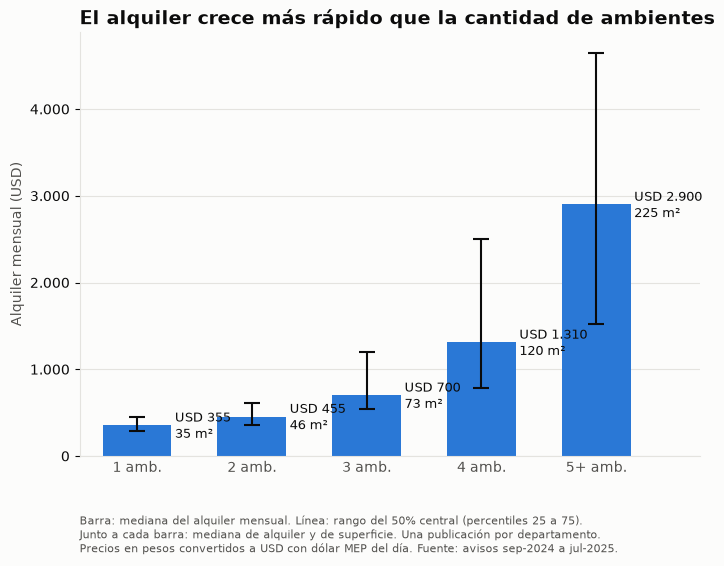

In [6]:
fig = precio_por_ambientes(por_ambientes)
guardar(fig, "02_precio_por_ambientes");

El precio total crece cada vez más rápido: +28% de 1 a 2 ambientes, +54% de 2 a 3, +87% de 3 a 4 y +121% de 4 a 5+.

Sin embargo, la mediana de USD/m² es casi constante entre 1 y 3 ambientes (≈ USD 10) y sube recién en 4 y 5+. La tabla muestra una posible explicación: **los departamentos grandes se concentran en el corredor norte** (52% de los monoambientes contra 88% de los 5+ ambientes) y se publican mayoritariamente en dólares.

Para separar el efecto "tamaño" del efecto "barrio" se compara el USD/m² de 2 y 4 ambientes **dentro de cada barrio**.

In [7]:
chico_vs_grande = usd_m2_por_ambientes_en_barrio(deptos, chico=2, grande=4)
chico_vs_grande

,usd_m2_2_amb,usd_m2_4_amb,diferencia_%
barrio,,,
Almagro,9.2,6.9,-25.7
Villa Crespo,9.6,7.6,-21.0
Balvanera,8.2,6.7,-18.0
Flores,8.0,6.9,-14.3
Colegiales,10.1,8.7,-14.1
San Nicolás,8.5,7.8,-7.9
Villa Urquiza,9.7,9.1,-6.8
Caballito,9.2,8.6,-6.7
Recoleta,10.2,10.0,-1.9


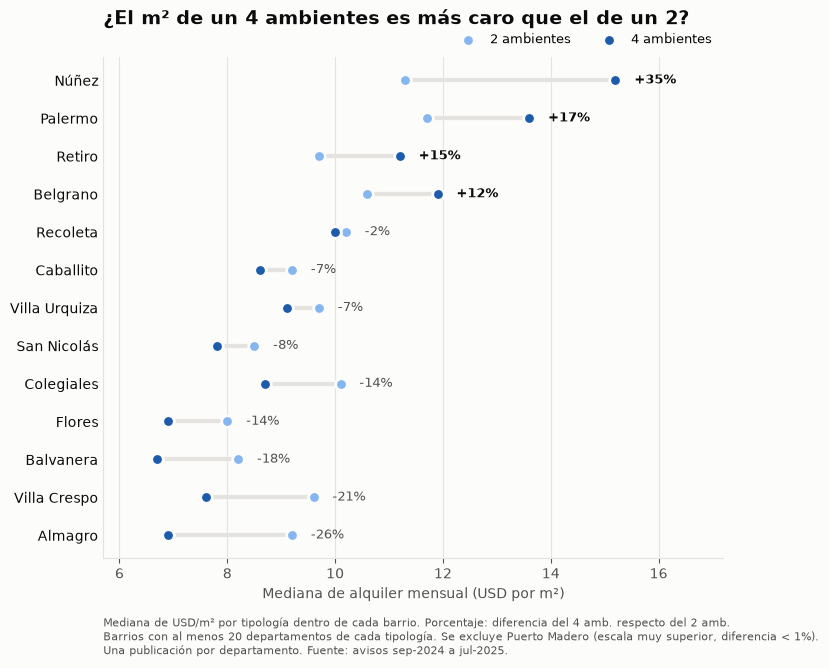

In [8]:
fig = usd_m2_chico_vs_grande(chico_vs_grande, excluir=["Puerto Madero"])
guardar(fig, "03_usd_m2_2_vs_4_ambientes");

### Conclusiones

- **El alquiler crece más rápido que la cantidad de ambientes.** Un 4 ambientes (USD 1.310) cuesta casi 3 veces lo que un 2 ambientes (USD 455), porque tiene 2,6 veces más superficie (120 contra 46 m²).
- **El m² más caro de los departamentos grandes es un efecto de composición, no de tamaño.** Dentro de un mismo barrio, en 9 de los 14 barrios analizados el m² de un 4 ambientes es **más barato** que el de un 2 ambientes: entre 7% y 26% menos en Almagro, Villa Crespo, Balvanera, Flores, Colegiales, San Nicolás, Villa Urquiza y Caballito, y apenas 2% menos en Recoleta.
- **La excepción es el norte premium:** en Núñez (+35%), Palermo (+17%), Retiro (+15%) y Belgrano (+12%) el m² de los departamentos grandes es más caro. Ahí los 4 ambientes suelen ser unidades de categoría (amenities, cochera, torres), un segmento distinto del de los 2 ambientes.
- **Implicancia práctica:** fuera del corredor norte, quien necesita más espacio obtiene más m² por dólar si alquila un departamento más grande, en lugar de pagar el m² más caro de las unidades chicas.

**Limitación:** la comparación por barrio no controla otras características (antigüedad, amenities, cochera) que no están disponibles de forma estructurada en el dataset.

## 3. ¿Qué relación hay entre superficie, ambientes y precio?

Se mide la **elasticidad precio-superficie**, que indica cuánto sube el precio (en %) cuando la superficie sube un 1%. Una elasticidad de 1 significa que el precio es proporcional a los m². Se calcula para toda la ciudad y también dentro de cada barrio, para descontar el efecto de la ubicación.

In [9]:
elasticidad_global = elasticidad_precio_superficie(deptos)
elasticidad_barrio = elasticidad_precio_superficie(deptos, por_barrio=True)
correlacion = deptos["precio_usd"].corr(deptos["m2"].astype(float))

print(f"Elasticidad en toda la ciudad: {elasticidad_global:.2f}")
print(f"Elasticidad dentro de cada barrio: {elasticidad_barrio:.2f}")
print(f"Correlación precio-superficie: {correlacion:.2f}")

Elasticidad en toda la ciudad: 1.13
Elasticidad dentro de cada barrio: 1.01
Correlación precio-superficie: 0.82


In [10]:
por_superficie = usd_m2_por_superficie(deptos)
por_superficie

,propiedades,mediana_usd_m2,mediana_precio_usd
superficie,,,
15-30 m²,2521,11.0,290.9
30-40 m²,7365,9.9,356.3
40-50 m²,5965,9.8,450.0
50-70 m²,5797,9.8,591.0
70-100 m²,3709,10.0,819.1
100-150 m²,1902,12.0,"1,500.0"
150+ m²,1779,14.9,"3,500.0"


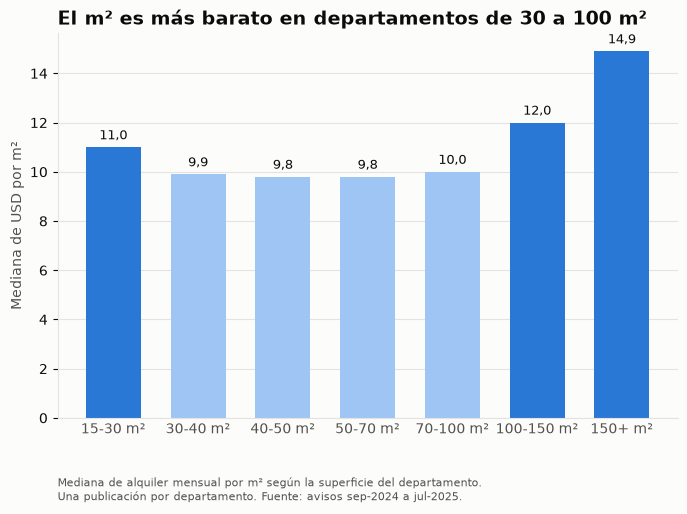

In [11]:
fig = usd_m2_por_superficie_chart(por_superficie)
guardar(fig, "04_usd_m2_por_superficie");

### Conclusiones

- **Dentro de un barrio, el precio es proporcional a la superficie** (elasticidad 1,01): un departamento 10% más grande cuesta un 10% más. En toda la ciudad la elasticidad es algo mayor (1,13), porque los departamentos grandes están en barrios más caros. Es el mismo efecto de composición de la sección 2.
- **La superficie es la variable que más explica el precio:** la correlación es de 0,82.
- **El USD/m² tiene forma de U:**
  - Los departamentos de menos de 30 m² pagan un 12% más por m² (USD 11,0), porque hay costos fijos (cocina, baño) repartidos en poca superficie.
  - Entre 30 y 100 m², el m² se mantiene estable en ≈ USD 9,8 a 10.
  - Por encima de 100 m², sube hasta USD 14,9, por el segmento premium.
- La cantidad de ambientes no agrega mucha información por encima de la superficie: es, en buena medida, otra forma de medir el tamaño (ver sección 2).

## 4. ¿Qué barrios ofrecen la mejor relación entre precio y superficie?

El ranking de USD/m² de la sección 1 ya responde esta pregunta de forma técnica. Para hacerla más concreta se plantea desde el lado de quien busca alquilar: **con un presupuesto en torno a la mediana de CABA (USD 450 a 550 por mes), ¿cuántos m² se consiguen en cada barrio?**

In [12]:
PRESUPUESTO_MIN, PRESUPUESTO_MAX = 450, 550

con_presupuesto = m2_por_presupuesto(deptos, PRESUPUESTO_MIN, PRESUPUESTO_MAX)
con_presupuesto

,propiedades,mediana_m2,mediana_ambientes
barrio,,,
Balvanera,170,59.0,3.0
San Cristóbal,44,59.0,3.0
Villa del Parque,58,55.0,2.0
San Nicolás,127,55.0,2.0
Flores,109,55.0,2.0
Parque Chacabuco,32,54.0,2.0
Monserrat,71,54.0,2.0
Villa Devoto,55,52.0,2.0
Barracas,46,51.0,2.0


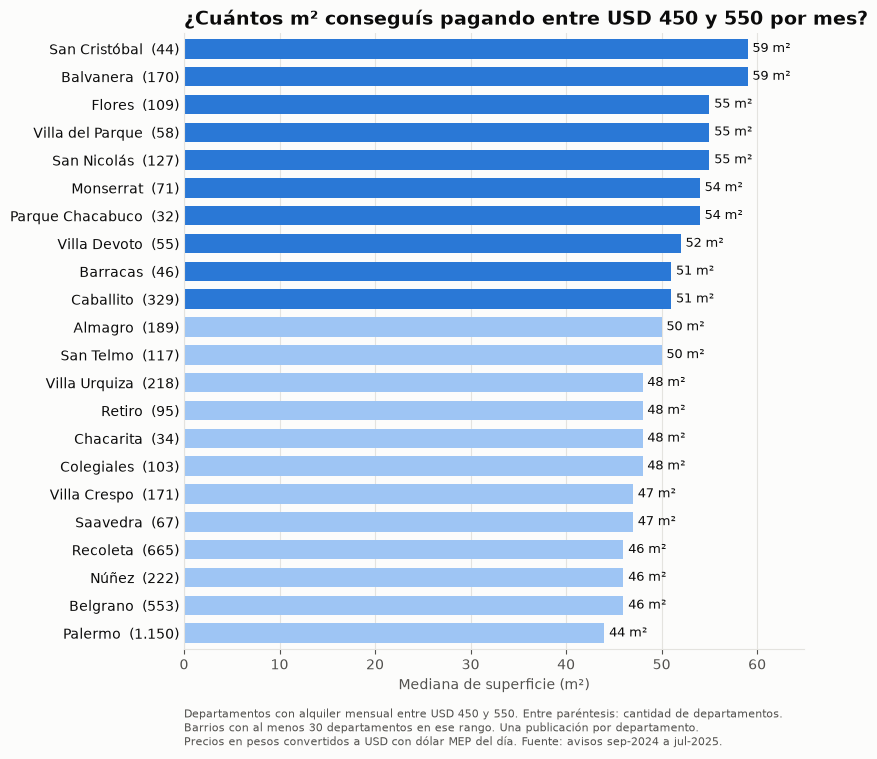

In [13]:
fig = m2_con_presupuesto(con_presupuesto, PRESUPUESTO_MIN, PRESUPUESTO_MAX)
guardar(fig, "05_m2_con_presupuesto");

### Conclusiones

- **Con el mismo presupuesto, en San Cristóbal o Balvanera se consiguen 59 m², contra 44 m² en Palermo: un 34% más de espacio.** En Balvanera y San Cristóbal ese presupuesto alcanza para un 3 ambientes; en el resto de los barrios, para un 2 ambientes.
- **Los barrios con mejor relación precio/superficie** son San Cristóbal, Balvanera, Flores, Villa del Parque y San Nicolás. Todos tienen buena conexión de transporte (subte o tren), lo que los hace una alternativa concreta al corredor norte.
- **En el corredor norte** (Palermo, Belgrano, Núñez, Recoleta) el mismo dinero alcanza para 44 a 46 m².
- Caballito y Almagro quedan en un punto medio (50 a 51 m²), con mucha oferta (329 y 189 departamentos en este rango de precio).

**Nota:** la referencia al transporte es contexto general, no surge del dataset.

## 5. ¿Cómo se comportan los precios a lo largo del tiempo?

### Los datos disponibles

El dataset tiene 5 fechas de scraping. Las tres de septiembre de 2024 (23, 24 y 29) se agrupan como un único período. Queda así:

| Período | Avisos |
|---|---|
| Septiembre 2024 | ≈ 15.700 |
| Marzo 2025 | ≈ 12.600 |
| Julio 2025 | ≈ 2.100 (scraping parcial) |

In [14]:
from src.analysis import (
    cambios_mismo_aviso,
    inflacion_acumulada,
    pct_en_usd_composicion_fija,
    pct_en_usd_por_ambientes,
    una_por_periodo,
    variacion_composicion_fija,
)
from src.charts import pct_usd_por_tipologia, variaciones_vs_referencias

periodos = una_por_periodo(df)
periodos["pesos_m2"] = periodos["precio_usd_m2"] * periodos["tc"]

inflacion = pd.read_csv("../data/external/inflacion.csv")
tipo_cambio = pd.read_csv("../data/external/tipo_cambio.csv", parse_dates=["fecha"]).set_index("fecha")

periodos.groupby("periodo").agg(
    avisos=("id", "size"),
    mediana_usd=("precio_usd", "median"),
    mediana_usd_m2=("precio_usd_m2", "median"),
)

,avisos,mediana_usd,mediana_usd_m2
periodo,,,
2024-09,15690,479.6,9.6
2025-03,12566,507.8,10.7
2025-07,2145,650.0,12.4


### Por qué no alcanza con comparar medianas

**Comparar la mediana de cada período es engañoso**, porque los avisos de cada período no son los mismos. Julio 2025, por ejemplo, tiene una proporción mayor de avisos en Puerto Madero y Palermo, así que su mediana sube aunque los precios no cambien.

Hay dos formas de comparar "lo mismo":

1. **El mismo aviso en dos fechas.** Suena ideal, pero tiene un problema: los avisos que siguen publicados meses después son justamente los que **no se alquilaron**. Esa muestra no representa al mercado (*sesgo de supervivencia*).
2. **Cada barrio consigo mismo (composición fija).** Se calcula la mediana de cada barrio en cada período y se promedian los barrios con los mismos pesos. Este es el método que se usa para medir la evolución.

In [15]:
# Método 1: el mismo aviso en sep-2024 y mar-2025
cambios_mismo_aviso(periodos, "2024-09", "2025-03")

,avisos,% sin cambio de precio,% suben,% bajan
currency,,,,
Dólares,766,63.7,25.6,10.7
Pesos,381,40.7,38.8,20.5


Más de la mitad de los avisos que siguen publicados 6 meses después **mantiene el mismo precio**, a pesar de una inflación del 13% en el período. Esto confirma el sesgo: son departamentos que no se alquilan y cuyos avisos no se actualizan. Por eso no se usa este método para medir la evolución del mercado.

### Evolución con composición fija: septiembre 2024 a marzo 2025

In [16]:
BASE, COMPARAR = "2024-09", "2025-03"

en_pesos = variacion_composicion_fija(periodos[periodos["currency"] == "$"], "pesos_m2", BASE, COMPARAR)
en_dolares = variacion_composicion_fija(periodos[periodos["currency"] == "USD"], "precio_usd_m2", BASE, COMPARAR)
ipc = inflacion_acumulada(inflacion, "2024-10", "2025-02")
mep = (tipo_cambio.loc["2025-03-09", "mep"] / tipo_cambio.loc["2024-09-23", "mep"] - 1) * 100

print(f"Alquileres en pesos (pesos/m²): {en_pesos['variacion_%']:+.1f}%  ({en_pesos['barrios']} barrios)")
print(f"Alquileres en dólares (USD/m²): {en_dolares['variacion_%']:+.1f}%  ({en_dolares['barrios']} barrios)")
print(f"Inflación oct-2024 a feb-2025: {ipc:+.1f}%")
print(f"Dólar MEP: {mep:+.1f}%")

Alquileres en pesos (pesos/m²): +16.3%  (35 barrios)
Alquileres en dólares (USD/m²): +16.1%  (15 barrios)
Inflación oct-2024 a feb-2025: +13.0%
Dólar MEP: +1.3%


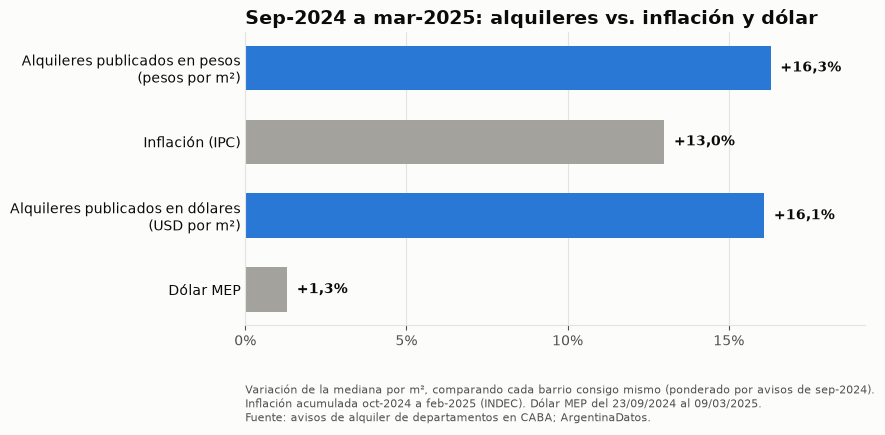

In [17]:
variaciones = pd.Series({
    "Alquileres publicados en pesos\n(pesos por m²)": en_pesos["variacion_%"],
    "Inflación (IPC)": ipc,
    "Alquileres publicados en dólares\n(USD por m²)": en_dolares["variacion_%"],
    "Dólar MEP": round(mep, 1),
})
fig = variaciones_vs_referencias(
    variaciones,
    referencias=["Inflación (IPC)", "Dólar MEP"],
    titulo="Sep-2024 a mar-2025: alquileres vs. inflación y dólar",
    nota=(
        "Variación de la mediana por m², comparando cada barrio consigo mismo (ponderado por avisos de sep-2024).\n"
        "Inflación acumulada oct-2024 a feb-2025 (INDEC). Dólar MEP del 23/09/2024 al 09/03/2025.\n"
        "Fuente: avisos de alquiler de departamentos en CABA; ArgentinaDatos."
    ),
)
guardar(fig, "06_variacion_precios");

### ¿Se dolarizó o se pesificó el mercado?

In [18]:
print("% de avisos en USD (composición fija):", pct_en_usd_composicion_fija(periodos, BASE, COMPARAR))
por_tipologia = pct_en_usd_por_ambientes(periodos)
por_tipologia

% de avisos en USD (composición fija): {'2024-09': 39.4, '2025-03': 31.1}


periodo,2024-09,2025-03,2025-07
tipologia,,,
1 amb.,27.8,20.2,22.2
2 amb.,33.3,23.3,29.3
3 amb.,46.2,33.1,47.7
4+ amb.,73.0,64.1,73.8


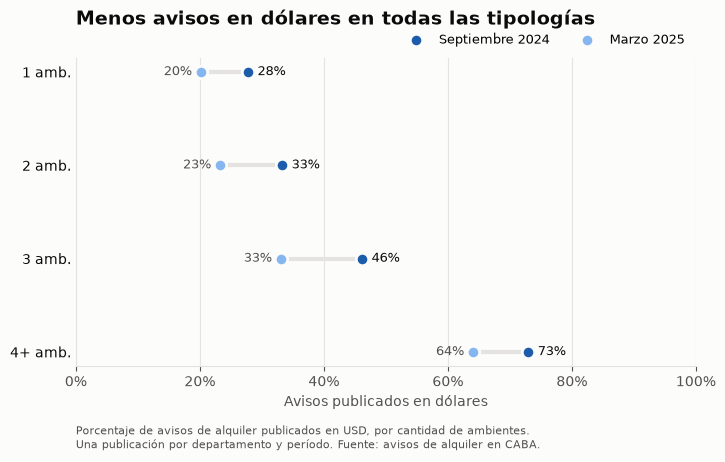

In [19]:
fig = pct_usd_por_tipologia(por_tipologia, BASE, COMPARAR, {BASE: "Septiembre 2024", COMPARAR: "Marzo 2025"})
guardar(fig, "07_pct_avisos_en_usd");

### Julio 2025: un dato preliminar

Julio tiene pocos avisos, así que solo 14 barrios alcanzan el mínimo de 30 avisos. Con esa salvedad:

In [20]:
jul_usd = variacion_composicion_fija(periodos, "precio_usd_m2", BASE, "2025-07")
jul_pesos = variacion_composicion_fija(periodos, "pesos_m2", BASE, "2025-07")
ipc_jul = inflacion_acumulada(inflacion, "2024-10", "2025-06")

print(f"Sep-2024 a jul-2025, todos los avisos ({jul_usd['barrios']} barrios):")
print(f"  En USD por m²:   {jul_usd['variacion_%']:+.1f}%")
print(f"  En pesos por m²: {jul_pesos['variacion_%']:+.1f}%  vs. inflación oct-2024 a jun-2025: {ipc_jul:+.1f}%")

Sep-2024 a jul-2025, todos los avisos (14 barrios):
  En USD por m²:   +23.9%
  En pesos por m²: +30.2%  vs. inflación oct-2024 a jun-2025: +24.3%


### Conclusiones

- **Entre septiembre 2024 y marzo 2025 los alquileres le ganaron a la inflación.** Los avisos en pesos subieron 16,3% por m², contra una inflación del 13,0%. Es una suba real de alrededor del 3%.
- **Alquilar se encareció en dólares.** Los avisos publicados en USD subieron 16,1% por m², mientras el dólar MEP casi no se movió (+1,3%). Medido en dólares, el mercado de alquileres de CABA se volvió más caro.
- **El mercado se pesificó.** Los avisos en dólares bajaron de 39% a 31% del total, controlando por barrio, y la baja se ve en todas las tipologías. Los departamentos grandes siguen siendo mayoritariamente en USD (64% de los 4+ ambientes en marzo).
- **Julio 2025 sugiere que la suba continuó** (+24% en USD/m² y +30% en pesos/m² contra 24% de inflación desde septiembre). Pero es un dato preliminar por el tamaño de la muestra.
- **Comparar el mismo aviso en dos fechas no sirve para medir el mercado.** Más de la mitad de los avisos que siguen publicados 6 meses después no cambió su precio: son los que no se alquilaron.

**Limitaciones:** son precios publicados (no de cierre), en solo 3 momentos del tiempo. Por eso no se puede ver la evolución mes a mes.